# Meeting 1 — Real-data baselines

**Question:** how well does the classifier recognise Egyptian Mau when it sees only 15 training photos of it
(and 70 of every other breed), and how much do two classical fixes help?

* **oversampling** — repeat the 15 photos until Egyptian Mau has 70 training examples (55 added);
* **augmentation** — add 55 randomly transformed copies of the 15 photos instead.

The classifier is EfficientNet-B0 (ImageNet weights) fine-tuned by `synth-train`, 5 seeds per run. Every choice is made
on the **validation** photos (20 per breed); the **test** photos (30 per breed) are used only at the end, for the runs
chosen here. The code for this meeting is `oversample()` and `augment()` in `src/synthdata/balance.py`.

In [1]:
import json
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from synthdata import balance, test, train
from synthdata.config import BUDGET, CLASSES, EVIDENCE_DIR, RUNS_DIR, TARGET
from synthdata.data import image_path, load_split, minority_training_photos, photos

pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)
EVIDENCE_DIR.mkdir(exist_ok=True)
print("device:", train.pick_device("auto"))

device: cuda


## 1. The data

The split in `data/split.csv` is fixed by the course and the same for everyone (`uv run synth-data` checks it).

In [2]:
split = pd.DataFrame([vars(p) for p in load_split()])
split.pivot_table(index="breed", columns="role", values="image", aggfunc="count")[["train", "val", "test"]]

role,train,val,test
breed,,,
Abyssinian,70,20,30
Bengal,70,20,30
Birman,70,20,30
Bombay,70,20,30
Egyptian Mau,15,20,30
Ragdoll,70,20,30
Russian Blue,70,20,30
Siamese,70,20,30


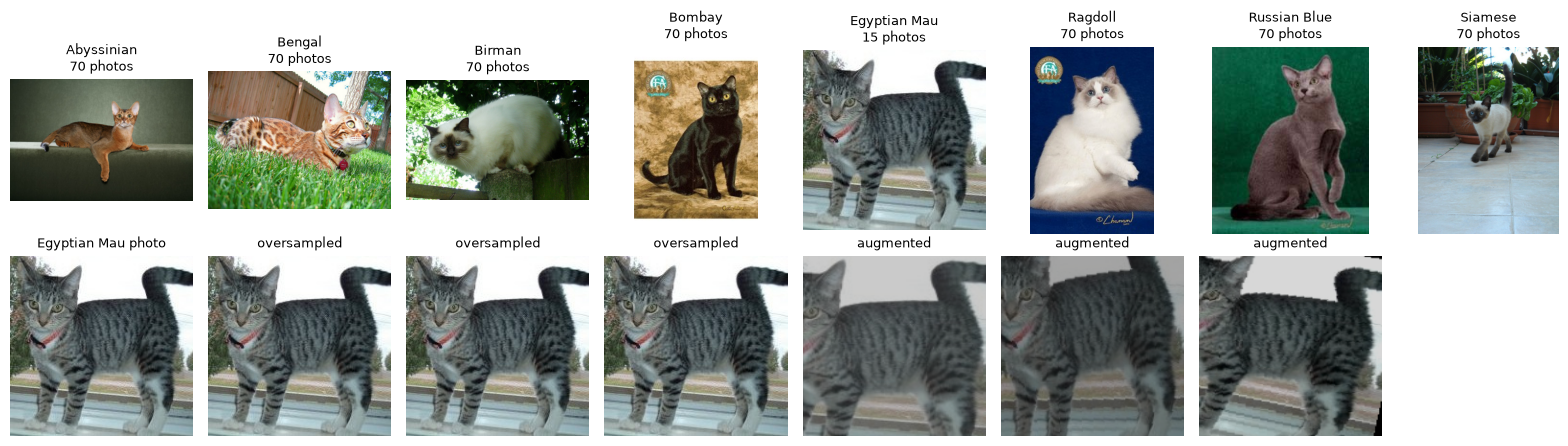

In [3]:
# One training photo of each breed with its training count, then what the two fixes add
# for one Egyptian Mau photo: three oversampled (identical) and three augmented copies.
train_photos = photos("train")
counts = Counter(p.breed for p in train_photos)
first = {p.breed: p.image for p in reversed(train_photos)}
mau = train.load_small(image_path(minority_training_photos()[0]))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, breed in zip(axes[0], CLASSES):
    ax.imshow(train.load_small(image_path(first[breed])))
    ax.set_title(f"{breed}\n{counts[breed]} photos", fontsize=9)
torch.manual_seed(0)
balance.AUGMENTATION = "moderate"
row = [("Egyptian Mau photo", mau)] + [("oversampled", mau)] * 3
row += [("augmented", balance.augment(mau.copy())) for _ in range(3)]
for ax, (title, image) in zip(axes[1], row):
    ax.imshow(image)
    ax.set_title(title, fontsize=9)
axes[1, -1].set_visible(False)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "m1-examples.png", dpi=100)

## 2. `oversample()` — and how I checked it

It must return exactly 55 names taken from the 15 Egyptian Mau training photos, repeating them **as evenly as
possible**, and use only the given `rng` so that a seed reproduces the run. Since 55 = 3 × 15 + 10, every photo is used
3 times and 10 photos chosen at random get a 4th copy; the list is then shuffled.

In [4]:
minority = minority_training_photos()
rows = []
for seed in range(5):
    chosen = balance.oversample(minority, BUDGET, random.Random(seed))
    uses = Counter(chosen)
    rows.append({
        "seed": seed,
        "length": len(chosen),
        "only training photos": set(chosen) <= set(minority),
        "photos used": len(uses),
        "times per photo": dict(sorted(Counter(uses.values()).items())),
        "same result again": chosen == balance.oversample(minority, BUDGET, random.Random(seed)),
    })
pd.DataFrame(rows)

,seed,length,only training photos,photos used,times per photo,same result again
0,0,55,True,15,"{3: 5, 4: 10}",True
1,1,55,True,15,"{3: 5, 4: 10}",True
2,2,55,True,15,"{3: 5, 4: 10}",True
3,3,55,True,15,"{3: 5, 4: 10}",True
4,4,55,True,15,"{3: 5, 4: 10}",True


Every seed gives 55 names from the training photos only; all 15 photos are used, 5 of them 3 times and 10 of them
4 times (the most even split possible); the same seed always gives the same list, and different seeds choose different
photos for the 4th copy. `synth-train` records the photos it actually added in `run.json`, so the same can be checked on
the finished runs:

In [5]:
for seed in range(5):
    added = json.loads((RUNS_DIR / "m1-oversample" / f"seed-{seed}" / "run.json").read_text())["added"]
    print(f"seed {seed}: {len(added)} added, uses per photo {sorted(Counter(added).values())}")

seed 0: 55 added, uses per photo [3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
seed 1: 55 added, uses per photo [3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
seed 2: 55 added, uses per photo [3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
seed 3: 55 added, uses per photo [3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
seed 4: 55 added, uses per photo [3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


## 3. `augment()` — and how I checked it

`synth-train` calls `augment()` every time an added copy is loaded, so each of the 55 copies looks different in every
epoch. **Important detail:** every training image (real, oversampled, or augmented) afterwards also goes through
`train.py`'s own light transform (crop of 75–100 % of the area, horizontal flip, small colour jitter). Oversampled copies
are therefore not pixel-identical during training either, and `augment()` has to add clearly *stronger* changes to make
a difference.

Two versions are in `balance.py` (chosen with the environment variable `SYNTH_AUGMENT`, default `moderate`):

| | moderate (default) | strong (the variant tried once) |
|---|---|---|
| rotation | ± 15° | ± 30° |
| crop (share of the area, resized back) | 50–100 % | 25–100 % |
| horizontal flip | 50 % | 50 % |
| colour jitter (brightness, contrast, saturation / hue) | 0.3 / 0.05 | 0.5 / 0.15 |
| greyscale | never | 20 % |

The check: the output is a PIL image of the same size, and looking at many samples, the cat stays recognisable.

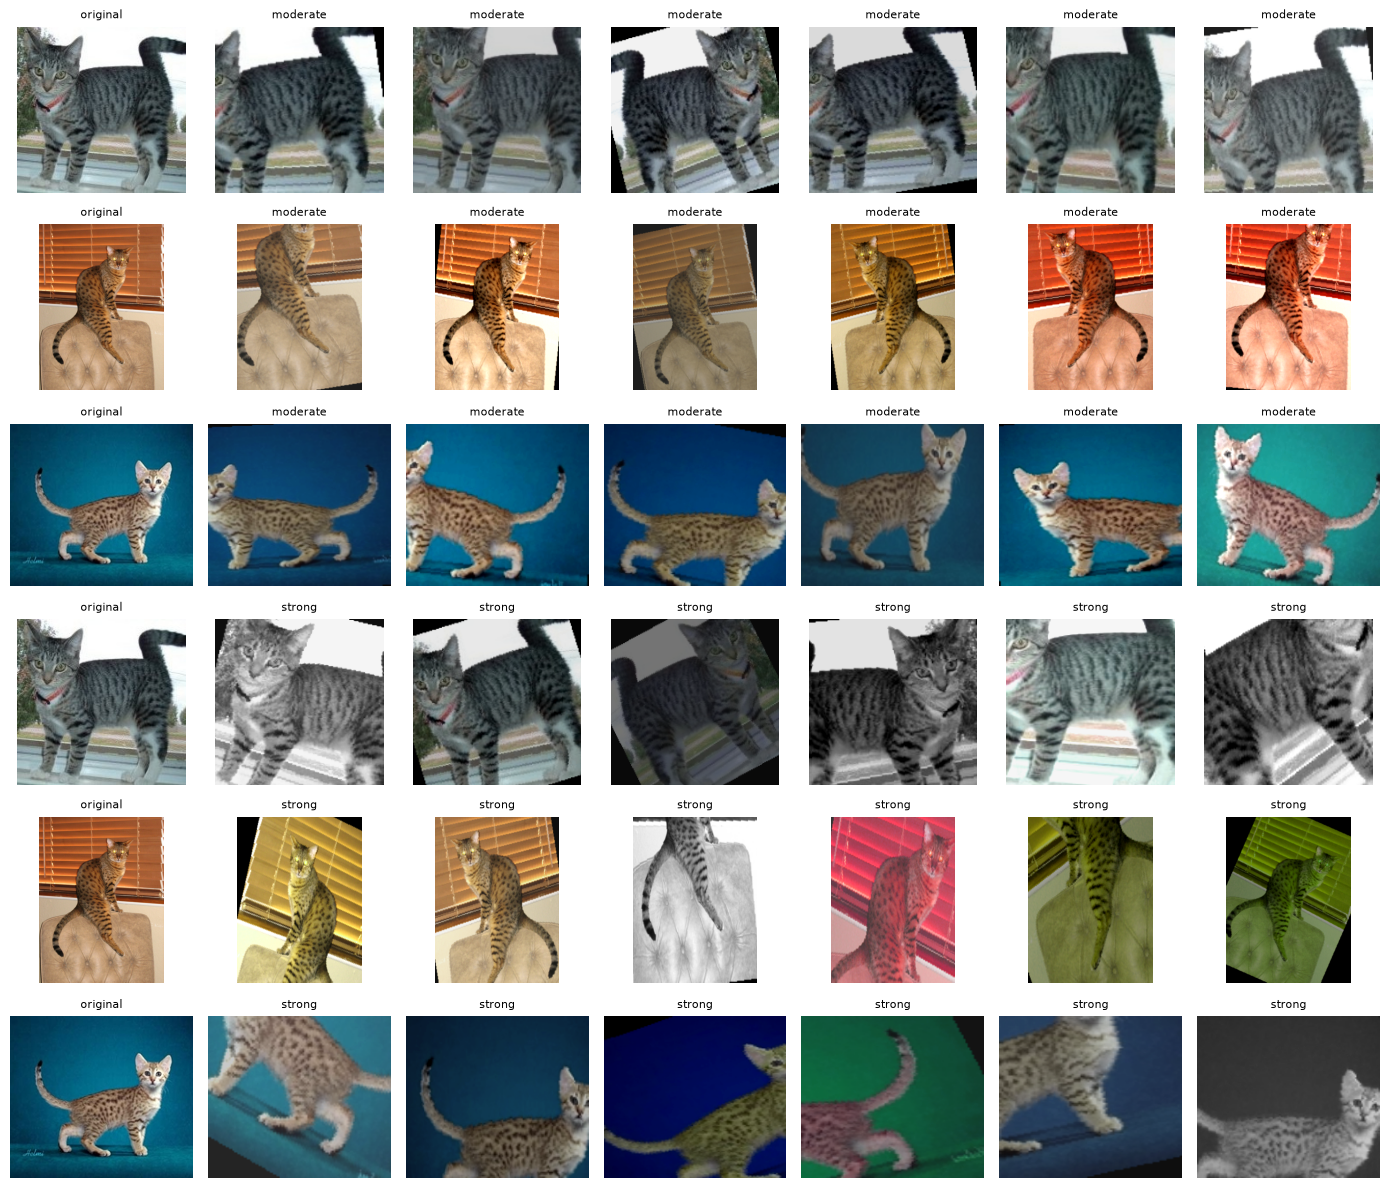

In [6]:
sources = [train.load_small(image_path(name)) for name in minority[:3]]
fig, axes = plt.subplots(6, 7, figsize=(14, 12))
torch.manual_seed(1)
for block, mode in enumerate(["moderate", "strong"]):
    balance.AUGMENTATION = mode
    for i, source in enumerate(sources):
        ax_row = axes[block * 3 + i]
        ax_row[0].imshow(source)
        ax_row[0].set_title("original", fontsize=8)
        for ax in ax_row[1:]:
            out = balance.augment(source.copy())
            assert isinstance(out, type(source)) and out.size == source.size
            ax.imshow(out)
            ax.set_title(mode, fontsize=8)
balance.AUGMENTATION = "moderate"
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "m1-augment-variants.png", dpi=80)

**Moderate** copies stay clearly recognisable: the whole cat, its spotted coat and its colours are kept, only
framing, angle and lighting change. **Strong** copies are much more varied, but some crops show only a patch of fur
without the head, and some are grey, so the cat is not always recognisable as an Egyptian Mau.

## 4. Training runs

The same commands as in the terminal (`uv run synth-train ...`), called from Python. Seeds that are already finished
are skipped, so running this cell again (or on another computer, after `git pull`) does not train again.

```bash
uv run synth-train --name m1-real --method real
uv run synth-train --name m1-oversample --method oversample
uv run synth-train --name m1-augment --method augment --tag augment=moderate
SYNTH_AUGMENT=strong uv run synth-train --name m1-augment-strong --method augment --tag augment=strong
```

In [7]:
train.main(["--name", "m1-real", "--method", "real"])
train.main(["--name", "m1-oversample", "--method", "oversample"])
train.main(["--name", "m1-augment", "--method", "augment", "--tag", "augment=moderate"])
balance.AUGMENTATION = "strong"
try:
    train.main(["--name", "m1-augment-strong", "--method", "augment", "--tag", "augment=strong"])
finally:
    balance.AUGMENTATION = "moderate"

m1-real: real, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m1-real\results.json


m1-oversample: oversample, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m1-oversample\results.json


m1-augment: augment, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m1-augment\results.json


m1-augment-strong: augment, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m1-augment-strong\results.json


## 5. Validation results (every seed)

Egyptian Mau recall is the share of the **20** Egyptian Mau validation photos recognised, so one photo = 0.05.
Macro-F1 is averaged over all eight breeds.

In [8]:
RUNS = ["m1-real", "m1-oversample", "m1-augment", "m1-augment-strong"]


def load_results(runs, filename="results.json"):
    rows = []
    for run in runs:
        for s in json.loads((RUNS_DIR / run / filename).read_text())["seeds"]:
            rows.append({"run": run, "seed": s["seed"], "egyptian_mau_recall": s["egyptian_mau_recall"],
                         "macro_f1": s["macro_f1"], **{f"recall {b}": s["recall"][b] for b in CLASSES}})
    return pd.DataFrame(rows)


def seed_table(results, runs):
    tables = []
    for metric in ["egyptian_mau_recall", "macro_f1"]:
        wide = results.pivot(index="seed", columns="run", values=metric)[runs]
        wide.loc["mean"] = wide.loc[0:4].mean()
        wide.loc["std"] = wide.loc[0:4].std()
        wide.columns = pd.MultiIndex.from_product([[metric], runs])
        tables.append(wide)
    return pd.concat(tables, axis=1)


val = load_results(RUNS)
val_table = seed_table(val, RUNS)
val_table.round(3).to_csv(EVIDENCE_DIR / "m1-validation.csv")
val_table.round(3)

egyptian_mau_recall                                            macro_f1                                           
                 m1-real m1-oversample m1-augment m1-augment-strong  m1-real m1-oversample m1-augment m1-augment-strong
seed                                                                                                                   
0                  0.450         0.650      0.700             0.750    0.861         0.885      0.886             0.879
1                  0.500         0.600      0.700             0.700    0.857         0.878      0.861             0.873
2                  0.500         0.650      0.700             0.750    0.869         0.885      0.879             0.892
3                  0.400         0.750      0.850             0.850    0.840         0.912      0.905             0.893
4                  0.600         0.700      0.700             0.800    0.859         0.911      0.898             0.906
mean               0.490         0.670      0.730             0.770    0.857         0.894      0.886             0.889
std                0.074         0.057      0.067             0.057    0.010         0.016      0.017             0.013

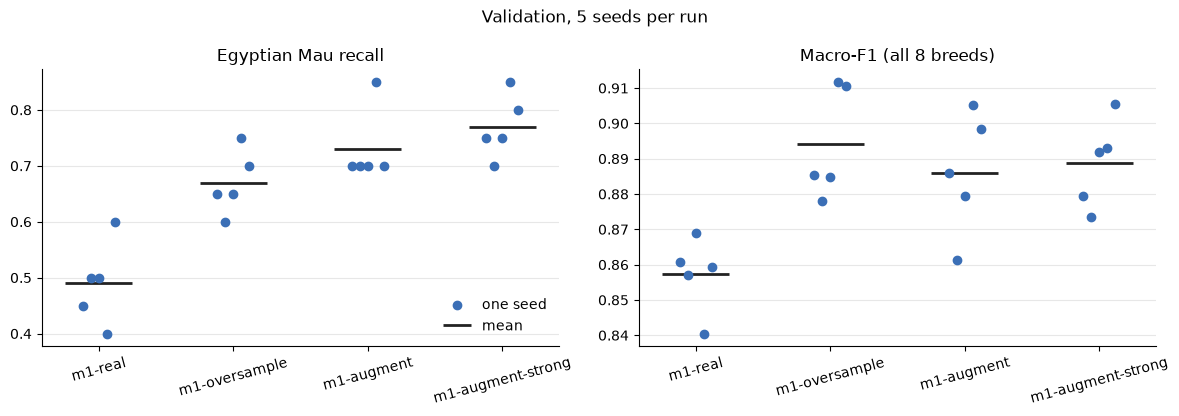

In [9]:
def seed_plot(results, runs, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, (metric, label) in zip(axes, [("egyptian_mau_recall", "Egyptian Mau recall"),
                                          ("macro_f1", "Macro-F1 (all 8 breeds)")]):
        for x, run in enumerate(runs):
            values = results.loc[results.run == run, metric].to_numpy()
            offsets = np.linspace(-0.12, 0.12, len(values))
            ax.scatter(x + offsets, values, s=36, color="#3b6fb6", zorder=3,
                       label="one seed" if x == 0 else None)
            ax.hlines(values.mean(), x - 0.25, x + 0.25, color="#222222", lw=2, zorder=2,
                      label="mean" if x == 0 else None)
        ax.set_xticks(range(len(runs)), runs, rotation=15)
        ax.set_title(label)
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=100)


seed_plot(val, RUNS, "Validation, 5 seeds per run", EVIDENCE_DIR / "m1-validation.png")

### Where do the Egyptian Mau mistakes go — and does it cost the other breeds?

First table: what the Egyptian Mau validation photos were predicted as, summed over the 5 seeds (20 photos × 5 seeds
= 100 predictions per run), plus how many **Bengal** photos were predicted as Egyptian Mau.
Second table: mean recall of every breed.

In [10]:
def confusion(run, filename="metrics.json"):
    return sum(np.array(json.loads((RUNS_DIR / run / f"seed-{k}" / filename).read_text())["confusion"])
               for k in range(5))


def mau_mistakes(runs, filename="metrics.json"):
    i, b = CLASSES.index(TARGET), CLASSES.index("Bengal")
    rows = {}
    for run in runs:
        total = confusion(run, filename)
        rows[run] = {**dict(zip(CLASSES, total[i])), "Bengal predicted as Egyptian Mau": total[b, i]}
    table = pd.DataFrame(rows).T
    return table.loc[:, table.sum() > 0]


def breed_recall(results):
    table = results.groupby("run", sort=False)[[f"recall {b}" for b in CLASSES]].mean()
    table.columns = CLASSES
    return table.round(2)


display(mau_mistakes(RUNS))
display(breed_recall(val))

,Abyssinian,Bengal,Egyptian Mau,Ragdoll,Russian Blue,Bengal predicted as Egyptian Mau
m1-real,10,26,49,0,15,1
m1-oversample,10,12,67,1,10,6
m1-augment,10,10,73,0,7,12
m1-augment-strong,9,9,77,0,5,14


,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
run,,,,,,,,
m1-real,0.94,0.85,0.87,1.00,0.49,0.86,1.0,0.90
m1-oversample,0.99,0.83,0.92,1.00,0.67,0.85,1.0,0.91
m1-augment,0.97,0.75,0.92,0.98,0.73,0.85,1.0,0.90
m1-augment-strong,0.96,0.73,0.90,0.99,0.77,0.85,1.0,0.92


### What the validation results show

* **Imbalanced (`m1-real`):** the classifier recognises about half of the Egyptian Mau photos (mean 0.49, seeds
  0.40–0.60), while the other breeds are at 0.85–1.00. Most mistakes are **Bengal** (26 of the 51 missed predictions),
  then Russian Blue and Abyssinian.
* **Oversampling** raises Egyptian Mau recall to 0.67 (0.60–0.75) and macro-F1 from 0.857 to 0.894. Every oversampling
  seed is at or above the best imbalanced seed, so this is a real difference, not seed noise.
* **Augmentation (moderate)** reaches 0.73 (0.70–0.85) with macro-F1 0.886. Against oversampling, the mean is higher by
  0.06, a bit more than one validation photo, but the seed ranges overlap (0.60–0.75 vs 0.70–0.85), so the two
  methods are **not clearly different** on validation.
* **The gain for Egyptian Mau partly costs Bengal**, mostly with augmentation: Bengal photos predicted as Egyptian Mau
  rise from 1 of 100 (real) to 6 (oversampling) and 12 (augmentation), and Bengal recall drops from 0.85 to 0.83 and
  0.75. Macro-F1 is still higher than without the fixes, so overall the trade is positive.

### The augmentation variant: strong instead of moderate

`m1-augment-strong` changes only `augment()` (stronger transforms, see the table in section 3). Its Egyptian Mau recall
is 0.77 (0.70–0.85) against 0.73 (0.70–0.85) for moderate: 0.04 higher on average, **less than one validation photo**,
with identical ranges, so the difference is within the seed spread and **not evidence** that stronger augmentation is
better. Macro-F1 is the same (0.889 vs 0.886) and Bengal recall slightly lower (0.73 vs 0.75). The likely reason it does
not help more: the strong copies add variety, but some of them no longer show a recognisable Egyptian Mau (a crop of fur
without the head, or a grey image), so they carry less useful information about the breed.

## 6. Choice (made on validation, before testing)

**The moderate `augment()` is kept**, so `m1-augment` is the augmentation baseline. The strong variant was 0.04 higher
in mean Egyptian Mau recall, less than one validation photo, with the same seed range, so there is no evidence that it
is better, and some of its copies no longer show a recognisable cat. The three runs tested are **`m1-real`,
`m1-oversample` and `m1-augment`**; `m1-augment-strong` is not tested.

## 7. Test results of the three baselines

```bash
uv run synth-test --run m1-real
uv run synth-test --run m1-oversample
uv run synth-test --run m1-augment
```

A run is tested only once: if its `test-results.json` already exists, the cell just reads it. (The trained models
`model.pt` are not committed, so a run can only be tested on the computer that trained it.)
Egyptian Mau recall is now the share of the **30** Egyptian Mau test photos, so one photo = 0.033.

In [11]:
TESTED = ["m1-real", "m1-oversample", "m1-augment"]
for run in TESTED:
    if (RUNS_DIR / run / "test-results.json").exists():
        print(f"{run}: already tested")
    else:
        test.main(["--run", run])

test_results = load_results(TESTED, "test-results.json")
test_table = seed_table(test_results, TESTED)
test_table.round(3).to_csv(EVIDENCE_DIR / "m1-test.csv")
test_table.round(3)

m1-real: already tested
m1-oversample: already tested
m1-augment: already tested


egyptian_mau_recall                          macro_f1                         
                 m1-real m1-oversample m1-augment  m1-real m1-oversample m1-augment
seed                                                                               
0                  0.433         0.700      0.733    0.846         0.875      0.883
1                  0.533         0.667      0.700    0.858         0.877      0.878
2                  0.500         0.733      0.733    0.865         0.891      0.882
3                  0.433         0.700      0.733    0.846         0.883      0.899
4                  0.633         0.700      0.733    0.868         0.874      0.878
mean               0.507         0.700      0.727    0.857         0.880      0.884
std                0.083         0.024      0.015    0.010         0.007      0.009

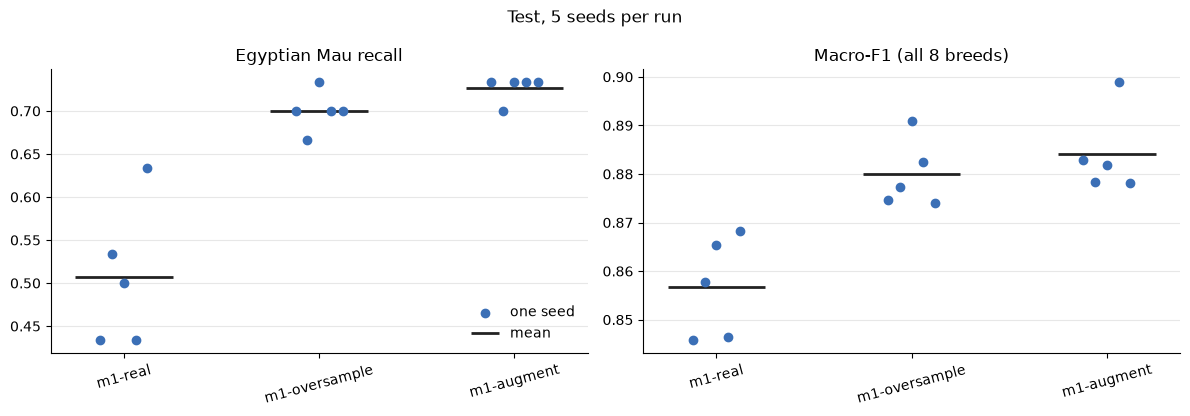

In [12]:
seed_plot(test_results, TESTED, "Test, 5 seeds per run", EVIDENCE_DIR / "m1-test.png")

In [13]:
means = pd.DataFrame({
    "val Mau recall": val.groupby("run")["egyptian_mau_recall"].mean(),
    "test Mau recall": test_results.groupby("run")["egyptian_mau_recall"].mean(),
    "val macro-F1": val.groupby("run")["macro_f1"].mean(),
    "test macro-F1": test_results.groupby("run")["macro_f1"].mean(),
}).loc[TESTED]
display(means.round(3))
display(mau_mistakes(TESTED, "test-metrics.json"))
display(breed_recall(test_results))

,val Mau recall,test Mau recall,val macro-F1,test macro-F1
run,,,,
m1-real,0.49,0.507,0.857,0.857
m1-oversample,0.67,0.700,0.894,0.880
m1-augment,0.73,0.727,0.886,0.884


,Abyssinian,Bengal,Egyptian Mau,Russian Blue,Siamese,Bengal predicted as Egyptian Mau
m1-real,4,44,76,26,0,0
m1-oversample,6,20,105,18,1,1
m1-augment,6,20,109,14,1,7


,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
run,,,,,,,,
m1-real,0.94,0.93,0.91,0.99,0.51,0.89,0.87,0.87
m1-oversample,0.92,0.90,0.91,0.97,0.70,0.88,0.85,0.91
m1-augment,0.93,0.86,0.91,0.99,0.73,0.88,0.87,0.91


### What the test results show

The test photos confirm the validation picture:

* **Imbalanced:** 0.507 mean Egyptian Mau recall (0.433–0.633, i.e. 13–19 of 30 photos); most misses are again
  **Bengal** (44 of the 74 missed predictions over 5 seeds), then Russian Blue (26).
* **Oversampling:** 0.700 (0.667–0.733), every seed above every imbalanced seed; macro-F1 0.857 → 0.880.
* **Augmentation (moderate):** 0.727 (0.700–0.733); macro-F1 0.884.
* **Oversampling vs augmentation:** augmentation is ahead by 0.027 on average, **less than one test photo**, and the
  seed ranges overlap, so on the test photos, too, the two classical fixes are **not clearly different**. The order
  of the means (imbalanced < oversampling < augmentation) is the same as on validation.
* **The Bengal trade-off is also there:** Bengal photos predicted as Egyptian Mau go from 0 of 150 (real) to 1
  (oversampling) and 7 (augmentation), and Bengal recall from 0.93 to 0.90 and 0.86. Macro-F1 still rises.

**Summary of Meeting 1:** both classical methods clearly improve Egyptian Mau recognition over the imbalanced data
(about 0.51 → 0.70–0.73 on test) without lowering macro-F1, while costing Bengal a little; between them there is no
clear difference.